# 03. Feature Engineering and Random Forest


### 1. IMPORT LIBRARIES

In [2]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


###   2. LOAD PROCESSED DATA

In [3]:
# ============================================================
# 2. LOAD PROCESSED DATA
# ============================================================

DATA_PATH = Path(
    r"C:\Users\ramganesh\OneDrive\Documents\SEM-3 PROJECTS\main project\smart-inventory-ai\data\processed_daily_sales.csv"
)

daily_sales = pd.read_csv(DATA_PATH)

daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])
daily_sales["StockCode"] = daily_sales["StockCode"].astype(str).str.strip()

daily_sales = daily_sales.sort_values(
    ["StockCode", "Date"]
).reset_index(drop=True)

print("Processed dataset loaded.")
print(f"Rows    : {len(daily_sales):,}")
print(f"Columns : {len(daily_sales.columns)}")
print(daily_sales.columns.tolist())

C:\Users\ramganesh\AppData\Local\Temp\ipykernel_30872\3414648284.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  daily_sales = pd.read_csv(DATA_PATH)


Processed dataset loaded.
Rows    : 1,464,584
Columns : 3
['StockCode', 'Date', 'UnitsSold']


In [4]:
daily_sales.head()

,StockCode,Date,UnitsSold
0,10002,2010-12-01,12
1,10002,2010-12-02,1
2,10002,2010-12-03,8
3,10002,2010-12-04,0
4,10002,2010-12-05,1


## 3. Rebuild the Future 7-Day Target

We intentionally **recalculate** `Future7DayDemand` instead of trusting an old copy in the CSV. This prevents stale or partially-created target values from surviving notebook reruns.

For date `T`:

**Future7DayDemand = sales from T+1 through T+7**.

In [5]:
# ============================================================
# CREATE / RECREATE TARGET
# ============================================================

target_column = "Future7DayDemand"

daily_sales[target_column] = (
    daily_sales
    .groupby("StockCode")["UnitsSold"]
    .transform(
        lambda x:
        x.shift(-1)
         .rolling(window=7, min_periods=7)
         .sum()
         .shift(-6)
    )
)

print("Future 7-day demand target recreated.")

display(
    daily_sales[
        ["StockCode", "Date", "UnitsSold", target_column]
    ].head(20)
)

Future 7-day demand target recreated.


,StockCode,Date,UnitsSold,Future7DayDemand
0,10002,2010-12-01,12,56.0
1,10002,2010-12-02,1,87.0
2,10002,2010-12-03,8,79.0
3,10002,2010-12-04,0,79.0
4,10002,2010-12-05,1,78.0
5,10002,2010-12-06,25,80.0
6,10002,2010-12-07,8,79.0
7,10002,2010-12-08,13,66.0
8,10002,2010-12-09,32,39.0
9,10002,2010-12-10,0,41.0


## 4. Remove Rows Without a Complete Target

The last seven calendar dates for each product cannot have a known future 7-day demand because those future days are outside the dataset.

These rows **must not be used for training or testing**.

This is different from missing *features*: we can fill some feature gaps, but we cannot invent a future target.

In [6]:
# ============================================================
# REMOVE INVALID / INCOMPLETE TARGET ROWS
# ============================================================

before_target_drop = len(daily_sales)

daily_sales = daily_sales.dropna(
    subset=[target_column]
).copy()

after_target_drop = len(daily_sales)

print(f"Rows before target filtering : {before_target_drop:,}")
print(f"Rows removed                 : {before_target_drop - after_target_drop:,}")
print(f"Rows remaining               : {after_target_drop:,}")

print(
    "\nRemaining target NaN:",
    daily_sales[target_column].isna().sum()
)

Rows before target filtering : 1,464,584
Rows removed                 : 27,412
Rows remaining               : 1,437,172

Remaining target NaN: 0


## 5. Lag Features

All lag features use only previous sales for the same product.

In [7]:
# ============================================================
# LAG FEATURES
# ============================================================

daily_sales["Lag_1"] = (
    daily_sales
    .groupby("StockCode")["UnitsSold"]
    .shift(1)
)

daily_sales["Lag_7"] = (
    daily_sales
    .groupby("StockCode")["UnitsSold"]
    .shift(7)
)

daily_sales["Lag_30"] = (
    daily_sales
    .groupby("StockCode")["UnitsSold"]
    .shift(30)
)

display(
    daily_sales[
        ["StockCode", "Date", "UnitsSold",
         "Lag_1", "Lag_7", "Lag_30"]
    ].head(20)
)

,StockCode,Date,UnitsSold,Lag_1,Lag_7,Lag_30
0,10002,2010-12-01,12,NaN,NaN,NaN
1,10002,2010-12-02,1,12.0,NaN,NaN
2,10002,2010-12-03,8,1.0,NaN,NaN
3,10002,2010-12-04,0,8.0,NaN,NaN
4,10002,2010-12-05,1,0.0,NaN,NaN
5,10002,2010-12-06,25,1.0,NaN,NaN
6,10002,2010-12-07,8,25.0,NaN,NaN
7,10002,2010-12-08,13,8.0,12.0,NaN
8,10002,2010-12-09,32,13.0,1.0,NaN
9,10002,2010-12-10,0,32.0,8.0,NaN


## 6. Rolling Features

We shift first so the current day's sales are not included.

`min_periods=1` means products with shorter history are not discarded unnecessarily.

In [8]:
# ============================================================
# ROLLING FEATURES
# ============================================================

daily_sales["RollingMean_7"] = (
    daily_sales
    .groupby("StockCode")["UnitsSold"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(window=7, min_periods=1)
         .mean()
    )
)

daily_sales["RollingMean_30"] = (
    daily_sales
    .groupby("StockCode")["UnitsSold"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(window=30, min_periods=1)
         .mean()
    )
)

display(
    daily_sales[
        ["StockCode", "Date", "UnitsSold",
         "RollingMean_7", "RollingMean_30"]
    ].head(20)
)

,StockCode,Date,UnitsSold,RollingMean_7,RollingMean_30
0,10002,2010-12-01,12,NaN,NaN
1,10002,2010-12-02,1,12.000000,12.000000
2,10002,2010-12-03,8,6.500000,6.500000
3,10002,2010-12-04,0,7.000000,7.000000
4,10002,2010-12-05,1,5.250000,5.250000
5,10002,2010-12-06,25,4.400000,4.400000
6,10002,2010-12-07,8,7.833333,7.833333
7,10002,2010-12-08,13,7.857143,7.857143
8,10002,2010-12-09,32,8.000000,8.500000
9,10002,2010-12-10,0,12.428571,11.111111


## 7. Historical Mean

In [9]:
daily_sales["HistoricalMean"] = (
    daily_sales
    .groupby("StockCode")["UnitsSold"]
    .transform(
        lambda x:
        x.shift(1)
         .expanding()
         .mean()
    )
)

display(
    daily_sales[
        ["StockCode", "Date", "UnitsSold", "HistoricalMean"]
    ].head(20)
)

,StockCode,Date,UnitsSold,HistoricalMean
0,10002,2010-12-01,12,NaN
1,10002,2010-12-02,1,12.000000
2,10002,2010-12-03,8,6.500000
3,10002,2010-12-04,0,7.000000
4,10002,2010-12-05,1,5.250000
5,10002,2010-12-06,25,4.400000
6,10002,2010-12-07,8,7.833333
7,10002,2010-12-08,13,7.857143
8,10002,2010-12-09,32,8.500000
9,10002,2010-12-10,0,11.111111


## 8. Calendar Features

In [10]:
daily_sales["DayOfWeek"] = daily_sales["Date"].dt.dayofweek
daily_sales["Month"] = daily_sales["Date"].dt.month
daily_sales["Year"] = daily_sales["Date"].dt.year

daily_sales[
    ["Date", "DayOfWeek", "Month", "Year"]
].head()

,Date,DayOfWeek,Month,Year
0,2010-12-01,2,12,2010
1,2010-12-02,3,12,2010
2,2010-12-03,4,12,2010
3,2010-12-04,5,12,2010
4,2010-12-05,6,12,2010


## 9. Add Historical Unit Price

Price is calculated from the original cleaned UK transactions.

We only forward-fill price within a product, so a missing price at a date is filled from an earlier known price, not a future price.

In [11]:
# ============================================================
# LOAD RAW DATA FOR PRICE FEATURE
# ============================================================

RAW_DATA_PATH = Path(
    r"C:\Users\ramganesh\OneDrive\Documents\SEM-3 PROJECTS\main project\smart-inventory-ai\data\Online Retail.xlsx"
)

raw_df = pd.read_excel(RAW_DATA_PATH)

raw_df["InvoiceDate"] = pd.to_datetime(
    raw_df["InvoiceDate"],
    errors="coerce"
)

raw_df["Country"] = raw_df["Country"].astype(str).str.strip()
raw_df["StockCode"] = raw_df["StockCode"].astype(str).str.strip()

raw_df = raw_df[
    raw_df["Country"] == "United Kingdom"
].copy()

raw_df = raw_df[
    ~raw_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

raw_df = raw_df[
    (raw_df["Quantity"] > 0) &
    (raw_df["UnitPrice"] > 0)
].copy()

raw_df = raw_df.drop_duplicates()

raw_df["Date"] = raw_df["InvoiceDate"].dt.normalize()

print(f"Clean raw UK rows for price: {len(raw_df):,}")

Clean raw UK rows for price: 479,985


In [12]:
# ============================================================
# DAILY AVERAGE PRICE
# ============================================================

daily_price = (
    raw_df
    .groupby(["StockCode", "Date"])["UnitPrice"]
    .mean()
    .reset_index()
    .rename(columns={"UnitPrice": "AvgUnitPrice"})
)

print(f"Daily product-price records: {len(daily_price):,}")
daily_price.head()

Daily product-price records: 261,326


,StockCode,Date,AvgUnitPrice
0,10002,2010-12-01,0.850
1,10002,2010-12-02,0.850
2,10002,2010-12-03,1.390
3,10002,2010-12-05,0.850
4,10002,2010-12-06,1.255


In [13]:
# ============================================================
# MERGE PRICE
# ============================================================

# Remove old price columns if the notebook is rerun
daily_sales = daily_sales.drop(
    columns=[
        col for col in
        ["AvgUnitPrice", "AvgUnitPrice_x", "AvgUnitPrice_y"]
        if col in daily_sales.columns
    ]
)

daily_sales = daily_sales.merge(
    daily_price,
    on=["StockCode", "Date"],
    how="left"
)

# Forward-fill only within product.
# No back-fill from future prices.
daily_sales["AvgUnitPrice"] = (
    daily_sales
    .groupby("StockCode")["AvgUnitPrice"]
    .transform(lambda x: x.ffill())
)

print("Average unit price merged successfully.")

Average unit price merged successfully.


## 10. Define ML Features

In [14]:
feature_columns = [
    "Lag_1",
    "Lag_7",
    "Lag_30",
    "RollingMean_7",
    "RollingMean_30",
    "HistoricalMean",
    "DayOfWeek",
    "Month",
    "Year",
    "AvgUnitPrice"
]

print("Features:")
for feature in feature_columns:
    print("-", feature)

print("\nTarget:")
print("-", target_column)

Features:
- Lag_1
- Lag_7
- Lag_30
- RollingMean_7
- RollingMean_30
- HistoricalMean
- DayOfWeek
- Month
- Year
- AvgUnitPrice

Target:
- Future7DayDemand


In [15]:
display(
    daily_sales[
        ["StockCode", "Date", "UnitsSold",
         target_column] + feature_columns
    ].head(20)
)

,StockCode,Date,UnitsSold,Future7DayDemand,Lag_1,Lag_7,Lag_30,RollingMean_7,RollingMean_30,HistoricalMean,DayOfWeek,Month,Year,AvgUnitPrice
0,10002,2010-12-01,12,56.0,NaN,NaN,NaN,NaN,NaN,NaN,2,12,2010,0.8500
1,10002,2010-12-02,1,87.0,12.0,NaN,NaN,12.000000,12.000000,12.000000,3,12,2010,0.8500
2,10002,2010-12-03,8,79.0,1.0,NaN,NaN,6.500000,6.500000,6.500000,4,12,2010,1.3900
3,10002,2010-12-04,0,79.0,8.0,NaN,NaN,7.000000,7.000000,7.000000,5,12,2010,1.3900
4,10002,2010-12-05,1,78.0,0.0,NaN,NaN,5.250000,5.250000,5.250000,6,12,2010,0.8500
5,10002,2010-12-06,25,80.0,1.0,NaN,NaN,4.400000,4.400000,4.400000,0,12,2010,1.2550
6,10002,2010-12-07,8,79.0,25.0,NaN,NaN,7.833333,7.833333,7.833333,1,12,2010,1.6600
7,10002,2010-12-08,13,66.0,8.0,12.0,NaN,7.857143,7.857143,7.857143,2,12,2010,1.2550
8,10002,2010-12-09,32,39.0,13.0,1.0,NaN,8.000000,8.500000,8.500000,3,12,2010,1.0525
9,10002,2010-12-10,0,41.0,32.0,8.0,NaN,12.428571,11.111111,11.111111,4,12,2010,1.0525


## 11. Time-Based Train/Test Split

We use the same date boundary as the baseline experiment.

- Training: **2010-12-01 to 2011-09-19**
- Testing: **2011-09-20 to the last valid target date**

Rows with an incomplete future target were already removed before this split.

In [16]:
# ============================================================
# TIME-BASED SPLIT
# ============================================================

TRAIN_END = pd.Timestamp("2011-09-19")
TEST_START = pd.Timestamp("2011-09-20")

train = daily_sales[
    daily_sales["Date"] <= TRAIN_END
].copy()

test = daily_sales[
    daily_sales["Date"] >= TEST_START
].copy()

print("=" * 60)
print("TIME-BASED SPLIT")
print("=" * 60)

print(f"Training rows: {len(train):,}")
print(f"Testing rows : {len(test):,}")

print("\nTraining period:")
print(train["Date"].min().date(), "to", train["Date"].max().date())

print("\nTesting period:")
print(test["Date"].min().date(), "to", test["Date"].max().date())

TIME-BASED SPLIT
Training rows: 1,147,388
Testing rows : 289,784

Training period:
2010-12-01 to 2011-09-19

Testing period:
2011-09-20 to 2011-12-02


## 12. Handle Missing Feature Values

We never fill or alter the target.

Only input features are filled:
- Lag features → `0`
- Rolling features → training global sales mean if needed
- Historical mean → training global sales mean
- Price → training global price mean if no earlier price exists

All fallback statistics come from training data only.

In [17]:
# ============================================================
# TRAINING-ONLY FALLBACK VALUES
# ============================================================

global_sales_mean = train["UnitsSold"].mean()

global_price_mean = (
    train["AvgUnitPrice"]
    .dropna()
    .mean()
)

print(f"Training global sales mean: {global_sales_mean:.4f}")
print(f"Training global price mean: {global_price_mean:.4f}")

Training global sales mean: 2.5990
Training global price mean: 6.5198


In [18]:
# ============================================================
# FILL INPUT FEATURE GAPS
# ============================================================

lag_columns = ["Lag_1", "Lag_7", "Lag_30"]
rolling_columns = ["RollingMean_7", "RollingMean_30"]

for column in lag_columns:
    train[column] = train[column].fillna(0)
    test[column] = test[column].fillna(0)

for column in rolling_columns:
    train[column] = train[column].fillna(global_sales_mean)
    test[column] = test[column].fillna(global_sales_mean)

train["HistoricalMean"] = train["HistoricalMean"].fillna(global_sales_mean)
test["HistoricalMean"] = test["HistoricalMean"].fillna(global_sales_mean)

train["AvgUnitPrice"] = train["AvgUnitPrice"].fillna(global_price_mean)
test["AvgUnitPrice"] = test["AvgUnitPrice"].fillna(global_price_mean)

print("Input feature gaps handled.")

Input feature gaps handled.


## 13. Final Data Validation

The target must contain **zero** missing values. If it does not, the notebook stops before model training.

In [19]:
# ============================================================
# FINAL SAFETY CHECK
# ============================================================

print("NaN in X_train:", train[feature_columns].isnull().sum().sum())
print("NaN in X_test :", test[feature_columns].isnull().sum().sum())
print("NaN in y_train:", train[target_column].isnull().sum())
print("NaN in y_test :", test[target_column].isnull().sum())

assert train[feature_columns].isnull().sum().sum() == 0
assert test[feature_columns].isnull().sum().sum() == 0
assert train[target_column].isnull().sum() == 0
assert test[target_column].isnull().sum() == 0

print("\nAll modelling inputs and targets are complete.")

NaN in X_train: 0
NaN in X_test : 0
NaN in y_train: 0
NaN in y_test : 0

All modelling inputs and targets are complete.


## 14. Prepare X and y

In [20]:
X_train = train[feature_columns]
y_train = train[target_column]

X_test = test[feature_columns]
y_test = test[target_column]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (1147388, 10)
y_train: (1147388,)
X_test : (289784, 10)
y_test : (289784,)


## 15. Recalculate Baselines on the Same Valid Data

Because incomplete target rows were removed, we calculate Level 0 and Level 1 again on the exact train/test data used by Random Forest.

This is the fair comparison to use for this experiment.

In [21]:
# ============================================================
# LEVEL 0 — GLOBAL MEAN
# ============================================================

level_0_prediction = y_train.mean()

level_0_pred_test = np.full(
    len(y_test),
    level_0_prediction
)

level_0_mae = mean_absolute_error(
    y_test,
    level_0_pred_test
)

print(f"Level 0 prediction: {level_0_prediction:.4f}")
print(f"Level 0 MAE       : {level_0_mae:.4f}")

Level 0 prediction: 18.3149
Level 0 MAE       : 39.1013


In [22]:
# ============================================================
# LEVEL 1 — PRODUCT HISTORICAL MEAN
# ============================================================

product_mean = (
    train
    .groupby("StockCode")[target_column]
    .mean()
)

level_1_pred_test = (
    test["StockCode"]
    .map(product_mean)
    .fillna(level_0_prediction)
)

level_1_mae = mean_absolute_error(
    y_test,
    level_1_pred_test
)

print(f"Level 1 MAE: {level_1_mae:.4f}")

Level 1 MAE: 28.5646


## 16. Train Random Forest

In [23]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created.")

Random Forest model created.


In [24]:
print("Training Random Forest...")

rf_model.fit(
    X_train,
    y_train
)

print("Training completed.")

Training Random Forest...
Training completed.


## 17. Generate Predictions

In [25]:
y_pred = rf_model.predict(X_test)

print("Predictions generated.")
print("Number of predictions:", len(y_pred))

Predictions generated.
Number of predictions: 289784


## 18. Evaluate Random Forest

In [26]:
rf_mae = mean_absolute_error(
    y_test,
    y_pred
)

print("=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)
print(f"Random Forest MAE: {rf_mae:.4f}")

RANDOM FOREST RESULTS
Random Forest MAE: 26.8363


## 19. Compare All Models

In [27]:
results = pd.DataFrame({
    "Model": [
        "Level 0 - Global Mean",
        "Level 1 - Product Historical Mean",
        "Random Forest"
    ],
    "MAE": [
        level_0_mae,
        level_1_mae,
        rf_mae
    ]
})

results

,Model,MAE
0,Level 0 - Global Mean,39.101336
1,Level 1 - Product Historical Mean,28.564631
2,Random Forest,26.836333


In [28]:
improvement_vs_level1 = (
    (level_1_mae - rf_mae) / level_1_mae
) * 100

print(f"Improvement over Level 1: {improvement_vs_level1:.2f}%")

if rf_mae < level_1_mae:
    print("SUCCESS: Random Forest beats Level 1.")
else:
    print("Random Forest does not beat Level 1 yet.")

Improvement over Level 1: 6.05%
SUCCESS: Random Forest beats Level 1.


## 20. Actual vs Predicted

In [29]:
comparison = test[
    ["StockCode", "Date", target_column]
].copy()

comparison = comparison.rename(
    columns={target_column: "Actual"}
)

comparison["Predicted"] = y_pred
comparison["AbsoluteError"] = (
    comparison["Actual"] - comparison["Predicted"]
).abs()

comparison.head(20)

,StockCode,Date,Actual,Predicted,AbsoluteError
293,10002,2011-09-20,0.0,0.810848,0.810848
294,10002,2011-09-21,0.0,0.810848,0.810848
295,10002,2011-09-22,0.0,0.810848,0.810848
296,10002,2011-09-23,0.0,0.810848,0.810848
297,10002,2011-09-24,0.0,0.810848,0.810848
298,10002,2011-09-25,0.0,0.810848,0.810848
299,10002,2011-09-26,0.0,0.810848,0.810848
300,10002,2011-09-27,0.0,0.810848,0.810848
301,10002,2011-09-28,0.0,0.810848,0.810848
302,10002,2011-09-29,0.0,0.810848,0.810848


## 21. Zero-Demand Analysis

In [30]:
zero_count = (y_test == 0).sum()
total_count = len(y_test)

print(f"Total test observations : {total_count:,}")
print(f"Zero-demand observations: {zero_count:,}")
print(
    f"Zero-demand percentage  : "
    f"{zero_count / total_count * 100:.2f}%"
)

display(y_test.describe())

Total test observations : 289,784
Zero-demand observations: 125,454
Zero-demand percentage  : 43.29%


count    289784.000000
mean         34.462589
std         188.221232
min           0.000000
25%           0.000000
50%           2.000000
75%          24.000000
max       80995.000000
Name: Future7DayDemand, dtype: float64

## 22. Feature Importance

In [31]:
importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
4,RollingMean_30,0.416632
5,HistoricalMean,0.240501
3,RollingMean_7,0.096616
9,AvgUnitPrice,0.091635
7,Month,0.070331
0,Lag_1,0.022088
2,Lag_30,0.018846
6,DayOfWeek,0.015569
1,Lag_7,0.014249
8,Year,0.013533


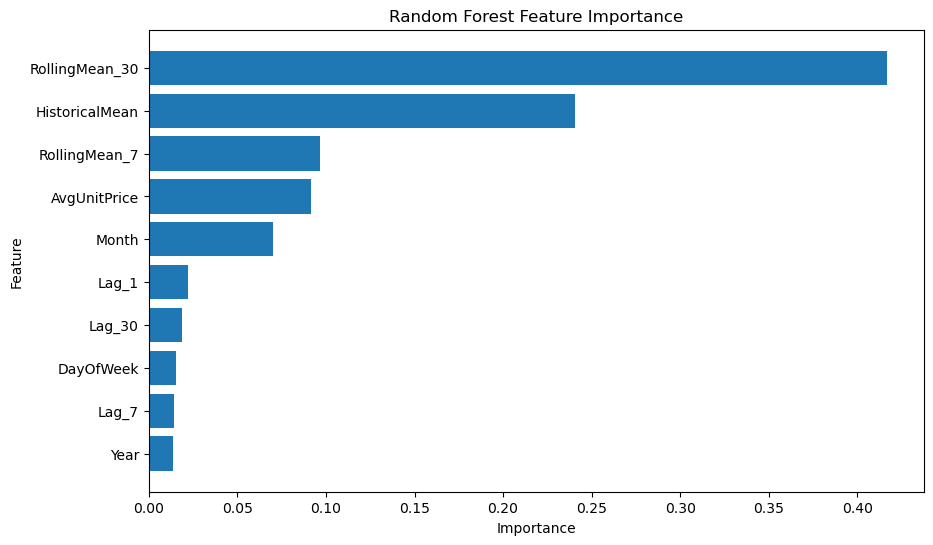

In [32]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

## 23. Save Results

In [33]:
RESULTS_PATH = Path("results/random_forest_results.csv")
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

results.to_csv(
    RESULTS_PATH,
    index=False
)

print(f"Results saved to: {RESULTS_PATH}")

Results saved to: results\random_forest_results.csv


In [34]:
PREDICTIONS_PATH = Path(
    "results/random_forest_predictions.csv"
)

comparison.to_csv(
    PREDICTIONS_PATH,
    index=False
)

print(f"Predictions saved to: {PREDICTIONS_PATH}")

Predictions saved to: results\random_forest_predictions.csv


## Final Experiment Summary

This notebook uses the same valid target definition for all three models.

### Reference from the previous baseline notebook
- Level 0 MAE: **39.1022**
- Level 1 MAE: **28.5688**

### Important
The baseline values above are historical reference values. The `results` table in this notebook recalculates Level 0 and Level 1 on the exact target-valid rows used by Random Forest. Use the recalculated values for the final model comparison if they differ.

In [35]:
# Inspect the aggregated dataset before feature engineering

print("Dataset shape:")
print(aggregated_df.shape)

print("\nColumn names:")
print(aggregated_df.columns.tolist())

print("\nData types:")
print(aggregated_df.dtypes)

print("\nFirst five rows:")
display(aggregated_df.head())

print("\nMissing values:")
print(aggregated_df.isnull().sum())

Dataset shape:


NameError: name 'aggregated_df' is not defined

In [36]:
# Find existing pandas DataFrames in the current notebook session

import pandas as pd

dataframes = {
    name: obj.shape
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

print("Available DataFrames:")

for name, shape in dataframes.items():
    print(f"{name}: {shape}")

Available DataFrames:
_: (10, 2)
__: (20, 5)
___: (3, 2)
daily_sales: (1437172, 14)
_4: (5, 3)
_10: (5, 4)
raw_df: (479985, 9)
daily_price: (261326, 3)
_12: (5, 3)
train: (1147388, 14)
test: (289784, 14)
X_train: (1147388, 10)
X_test: (289784, 10)
results: (3, 2)
_27: (3, 2)
comparison: (289784, 5)
_29: (20, 5)
importance: (10, 2)
_31: (10, 2)


In [37]:
import pandas as pd

print("=" * 60)
print("DAILY SALES DATASET")
print("=" * 60)

print("\nShape:")
print(daily_sales.shape)

print("\nColumns:")
print(daily_sales.columns.tolist())

print("\nData types:")
print(daily_sales.dtypes)

print("\nFirst 5 rows:")
display(daily_sales.head())

print("\nLast 5 rows:")
display(daily_sales.tail())

print("\nMissing values:")
print(daily_sales.isnull().sum())

DAILY SALES DATASET

Shape:
(1437172, 14)

Columns:
['StockCode', 'Date', 'UnitsSold', 'Future7DayDemand', 'Lag_1', 'Lag_7', 'Lag_30', 'RollingMean_7', 'RollingMean_30', 'HistoricalMean', 'DayOfWeek', 'Month', 'Year', 'AvgUnitPrice']

Data types:
StockCode                   object
Date                datetime64[ns]
UnitsSold                    int64
Future7DayDemand           float64
Lag_1                      float64
Lag_7                      float64
Lag_30                     float64
RollingMean_7              float64
RollingMean_30             float64
HistoricalMean             float64
DayOfWeek                    int32
Month                        int32
Year                         int32
AvgUnitPrice               float64
dtype: object

First 5 rows:


,StockCode,Date,UnitsSold,Future7DayDemand,Lag_1,Lag_7,Lag_30,RollingMean_7,RollingMean_30,HistoricalMean,DayOfWeek,Month,Year,AvgUnitPrice
0,10002,2010-12-01,12,56.0,NaN,NaN,NaN,NaN,NaN,NaN,2,12,2010,0.85
1,10002,2010-12-02,1,87.0,12.0,NaN,NaN,12.00,12.00,12.00,3,12,2010,0.85
2,10002,2010-12-03,8,79.0,1.0,NaN,NaN,6.50,6.50,6.50,4,12,2010,1.39
3,10002,2010-12-04,0,79.0,8.0,NaN,NaN,7.00,7.00,7.00,5,12,2010,1.39
4,10002,2010-12-05,1,78.0,0.0,NaN,NaN,5.25,5.25,5.25,6,12,2010,0.85



Last 5 rows:


,StockCode,Date,UnitsSold,Future7DayDemand,Lag_1,Lag_7,Lag_30,RollingMean_7,RollingMean_30,HistoricalMean,DayOfWeek,Month,Year,AvgUnitPrice
1437167,m,2011-11-28,0,0.0,0.0,0.0,0.0,0.0,0.0,0.002762,0,11,2011,2.55
1437168,m,2011-11-29,0,0.0,0.0,0.0,0.0,0.0,0.0,0.002755,1,11,2011,2.55
1437169,m,2011-11-30,0,0.0,0.0,0.0,0.0,0.0,0.0,0.002747,2,11,2011,2.55
1437170,m,2011-12-01,0,0.0,0.0,0.0,0.0,0.0,0.0,0.002740,3,12,2011,2.55
1437171,m,2011-12-02,0,0.0,0.0,0.0,0.0,0.0,0.0,0.002732,4,12,2011,2.55



Missing values:
StockCode                0
Date                     0
UnitsSold                0
Future7DayDemand         0
Lag_1                 3916
Lag_7                27412
Lag_30              117480
RollingMean_7         3916
RollingMean_30        3916
HistoricalMean        3916
DayOfWeek                0
Month                    0
Year                     0
AvgUnitPrice        211011
dtype: int64


In [38]:
print("TRAIN DATA")
print("Shape:", train.shape)
print("Columns:", train.columns.tolist())
display(train.head(3))

print("\nTEST DATA")
print("Shape:", test.shape)
print("Columns:", test.columns.tolist())
display(test.head(3))

print("\nTRAINING FEATURES")
print("Shape:", X_train.shape)
print("Columns:", X_train.columns.tolist())

print("\nTEST FEATURES")
print("Shape:", X_test.shape)
print("Columns:", X_test.columns.tolist())

TRAIN DATA
Shape: (1147388, 14)
Columns: ['StockCode', 'Date', 'UnitsSold', 'Future7DayDemand', 'Lag_1', 'Lag_7', 'Lag_30', 'RollingMean_7', 'RollingMean_30', 'HistoricalMean', 'DayOfWeek', 'Month', 'Year', 'AvgUnitPrice']


,StockCode,Date,UnitsSold,Future7DayDemand,Lag_1,Lag_7,Lag_30,RollingMean_7,RollingMean_30,HistoricalMean,DayOfWeek,Month,Year,AvgUnitPrice
0,10002,2010-12-01,12,56.0,0.0,0.0,0.0,2.598994,2.598994,2.598994,2,12,2010,0.85
1,10002,2010-12-02,1,87.0,12.0,0.0,0.0,12.000000,12.000000,12.000000,3,12,2010,0.85
2,10002,2010-12-03,8,79.0,1.0,0.0,0.0,6.500000,6.500000,6.500000,4,12,2010,1.39



TEST DATA
Shape: (289784, 14)
Columns: ['StockCode', 'Date', 'UnitsSold', 'Future7DayDemand', 'Lag_1', 'Lag_7', 'Lag_30', 'RollingMean_7', 'RollingMean_30', 'HistoricalMean', 'DayOfWeek', 'Month', 'Year', 'AvgUnitPrice']


,StockCode,Date,UnitsSold,Future7DayDemand,Lag_1,Lag_7,Lag_30,RollingMean_7,RollingMean_30,HistoricalMean,DayOfWeek,Month,Year,AvgUnitPrice
293,10002,2011-09-20,0,0.0,0.0,0.0,0.0,0.0,0.0,1.494881,1,9,2011,0.85
294,10002,2011-09-21,0,0.0,0.0,0.0,0.0,0.0,0.0,1.489796,2,9,2011,0.85
295,10002,2011-09-22,0,0.0,0.0,0.0,0.0,0.0,0.0,1.484746,3,9,2011,0.85



TRAINING FEATURES
Shape: (1147388, 10)
Columns: ['Lag_1', 'Lag_7', 'Lag_30', 'RollingMean_7', 'RollingMean_30', 'HistoricalMean', 'DayOfWeek', 'Month', 'Year', 'AvgUnitPrice']

TEST FEATURES
Shape: (289784, 10)
Columns: ['Lag_1', 'Lag_7', 'Lag_30', 'RollingMean_7', 'RollingMean_30', 'HistoricalMean', 'DayOfWeek', 'Month', 'Year', 'AvgUnitPrice']


In [39]:
print("EXISTING MODEL RESULTS")
display(results)

print("\nEXISTING MODEL COMPARISON")
display(comparison)

print("\nEXISTING FEATURE IMPORTANCE")
display(importance)

EXISTING MODEL RESULTS


,Model,MAE
0,Level 0 - Global Mean,39.101336
1,Level 1 - Product Historical Mean,28.564631
2,Random Forest,26.836333



EXISTING MODEL COMPARISON


,StockCode,Date,Actual,Predicted,AbsoluteError
293,10002,2011-09-20,0.0,0.810848,0.810848
294,10002,2011-09-21,0.0,0.810848,0.810848
295,10002,2011-09-22,0.0,0.810848,0.810848
296,10002,2011-09-23,0.0,0.810848,0.810848
297,10002,2011-09-24,0.0,0.810848,0.810848
...,...,...,...,...,...
1437167,m,2011-11-28,0.0,0.181436,0.181436
1437168,m,2011-11-29,0.0,0.181436,0.181436
1437169,m,2011-11-30,0.0,0.181436,0.181436
1437170,m,2011-12-01,0.0,0.181436,0.181436



EXISTING FEATURE IMPORTANCE


,Feature,Importance
4,RollingMean_30,0.416632
5,HistoricalMean,0.240501
3,RollingMean_7,0.096616
9,AvgUnitPrice,0.091635
7,Month,0.070331
0,Lag_1,0.022088
2,Lag_30,0.018846
6,DayOfWeek,0.015569
1,Lag_7,0.014249
8,Year,0.013533


In [40]:
import pandas as pd
import numpy as np

print("=" * 65)
print("NEXUS AI — TEMPORAL VALIDATION AUDIT")
print("=" * 65)

# 1. Verify date types
print("\n1. DATE TYPES")

print("daily_sales:", daily_sales["Date"].dtype)
print("train:", train["Date"].dtype)
print("test:", test["Date"].dtype)

# 2. Verify date ranges
print("\n2. DATE RANGES")

for name, frame in [
    ("daily_sales", daily_sales),
    ("train", train),
    ("test", test),
]:
    dates = pd.to_datetime(frame["Date"], errors="coerce")

    print(f"\n{name}")
    print("Rows:", len(frame))
    print("Minimum date:", dates.min())
    print("Maximum date:", dates.max())
    print("Invalid dates:", dates.isna().sum())

# 3. Check chronological boundaries
train_dates = pd.to_datetime(train["Date"], errors="coerce")
test_dates = pd.to_datetime(test["Date"], errors="coerce")

print("\n3. CHRONOLOGICAL SPLIT")

print("Latest training date:", train_dates.max())
print("Earliest test date:", test_dates.min())

if train_dates.max() < test_dates.min():
    print("PASS: Training dates precede test dates.")
else:
    print(
        "WARNING: Training and test dates overlap, "
        "or the split is not strictly chronological."
    )

# 4. Check product overlap
train_products = set(train["StockCode"].dropna().unique())
test_products = set(test["StockCode"].dropna().unique())

print("\n4. PRODUCT COVERAGE")

print("Training products:", len(train_products))
print("Test products:", len(test_products))
print("Products in both:", len(train_products & test_products))
print("Products only in test:", len(test_products - train_products))

# 5. Check target and feature availability
print("\n5. TARGET AND FEATURES")

target = "Future7DayDemand"

print("Target exists:", target in daily_sales.columns)

if target in daily_sales.columns:
    print("Target missing values:", daily_sales[target].isna().sum())
    print("Target minimum:", daily_sales[target].min())
    print("Target maximum:", daily_sales[target].max())

print("\nAudit complete.")

NEXUS AI — TEMPORAL VALIDATION AUDIT

1. DATE TYPES
daily_sales: datetime64[ns]
train: datetime64[ns]
test: datetime64[ns]

2. DATE RANGES

daily_sales
Rows: 1437172
Minimum date: 2010-12-01 00:00:00
Maximum date: 2011-12-02 00:00:00
Invalid dates: 0

train
Rows: 1147388
Minimum date: 2010-12-01 00:00:00
Maximum date: 2011-09-19 00:00:00
Invalid dates: 0

test
Rows: 289784
Minimum date: 2011-09-20 00:00:00
Maximum date: 2011-12-02 00:00:00
Invalid dates: 0

3. CHRONOLOGICAL SPLIT
Latest training date: 2011-09-19 00:00:00
Earliest test date: 2011-09-20 00:00:00
PASS: Training dates precede test dates.

4. PRODUCT COVERAGE
Training products: 3916
Test products: 3916
Products in both: 3916
Products only in test: 0

5. TARGET AND FEATURES
Target exists: True
Target missing values: 0
Target minimum: 0.0
Target maximum: 80995.0

Audit complete.


In [41]:
print("=" * 55)
print("NEXUS AI - AUDIT RESULTS")
print("=" * 55)

# 1. Verify chronological split
print("\n1. DATE SPLIT")

print("Training start:", train["Date"].min())
print("Training end:", train["Date"].max())

print("Test start:", test["Date"].min())
print("Test end:", test["Date"].max())

print(
    "Training/test dates overlap:",
    not (
        train["Date"].max() < test["Date"].min()
        or test["Date"].max() < train["Date"].min()
    )
)

# 2. Check product coverage
train_products = set(train["StockCode"].unique())
test_products = set(test["StockCode"].unique())

print("\n2. PRODUCT COVERAGE")

print("Training products:", len(train_products))
print("Test products:", len(test_products))
print("Products shared:", len(train_products & test_products))
print("Products only in test:", len(test_products - train_products))

# 3. Investigate target distribution
print("\n3. TARGET DISTRIBUTION")

print(
    daily_sales["Future7DayDemand"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    )
)

print("\nLargest target values:")
display(
    daily_sales.nlargest(10, "Future7DayDemand")[
        ["StockCode", "Date", "UnitsSold", "Future7DayDemand"]
    ]
)

# 4. Check duplicate product-date combinations
print("\n4. DUPLICATE CHECK")

print(
    "Duplicate product-date rows:",
    daily_sales.duplicated(["StockCode", "Date"]).sum()
)

NEXUS AI - AUDIT RESULTS

1. DATE SPLIT
Training start: 2010-12-01 00:00:00
Training end: 2011-09-19 00:00:00
Test start: 2011-09-20 00:00:00
Test end: 2011-12-02 00:00:00
Training/test dates overlap: False

2. PRODUCT COVERAGE
Training products: 3916
Test products: 3916
Products shared: 3916
Products only in test: 0

3. TARGET DISTRIBUTION
count    1.437172e+06
mean     2.157086e+01
std      1.960532e+02
min      0.000000e+00
50%      0.000000e+00
90%      5.000000e+01
95%      1.010000e+02
99%      3.260000e+02
99.9%    1.009829e+03
max      8.099500e+04
Name: Future7DayDemand, dtype: float64

Largest target values:


,StockCode,Date,UnitsSold,Future7DayDemand
904287,23843,2011-12-02,0,80995.0
740647,23166,2011-01-11,0,74215.0
740648,23166,2011-01-12,0,74215.0
740649,23166,2011-01-13,0,74215.0
740650,23166,2011-01-14,0,74215.0
740651,23166,2011-01-15,0,74215.0
740652,23166,2011-01-16,0,74215.0
740653,23166,2011-01-17,0,74215.0
1067192,84077,2011-10-20,192,5760.0
406634,22197,2011-12-01,279,5612.0



4. DUPLICATE CHECK
Duplicate product-date rows: 0


In [43]:
# Inspect suspicious Future7DayDemand values

cols = [
    "StockCode",
    "Date",
    "UnitsSold",
    "Future7DayDemand",
]

# Examine the product with repeated large target values
product_23166 = (
    daily_sales.loc[
        daily_sales["StockCode"].astype(str) == "23166",
        cols,
    ]
    .sort_values("Date")
)

print("Product 23166: first 15 observations")
display(product_23166.head(15))

print("\nProduct 23166: observations with the largest target")
display(
    product_23166.nlargest(10, "Future7DayDemand")
)

# Inspect the observation with the maximum target
print("\nObservation with the maximum target")

display(
    daily_sales.loc[
        daily_sales["Future7DayDemand"].idxmax(),
        cols,
    ].to_frame("Value")
)

# Examine the distribution of the target
print("\nTarget percentiles")

print(
    daily_sales["Future7DayDemand"].quantile(
        [0.50, 0.90, 0.95, 0.99, 0.999, 1.00]
    )
)

Product 23166: first 15 observations


,StockCode,Date,UnitsSold,Future7DayDemand
740606,23166,2010-12-01,0,0.0
740607,23166,2010-12-02,0,0.0
740608,23166,2010-12-03,0,0.0
740609,23166,2010-12-04,0,0.0
740610,23166,2010-12-05,0,0.0
740611,23166,2010-12-06,0,0.0
740612,23166,2010-12-07,0,0.0
740613,23166,2010-12-08,0,0.0
740614,23166,2010-12-09,0,0.0
740615,23166,2010-12-10,0,0.0



Product 23166: observations with the largest target


,StockCode,Date,UnitsSold,Future7DayDemand
740647,23166,2011-01-11,0,74215.0
740648,23166,2011-01-12,0,74215.0
740649,23166,2011-01-13,0,74215.0
740650,23166,2011-01-14,0,74215.0
740651,23166,2011-01-15,0,74215.0
740652,23166,2011-01-16,0,74215.0
740653,23166,2011-01-17,0,74215.0
740768,23166,2011-05-12,12,438.0
740767,23166,2011-05-11,0,436.0
740957,23166,2011-11-17,6,424.0



Observation with the maximum target


,Value
StockCode,23843
Date,2011-12-02 00:00:00
UnitsSold,0
Future7DayDemand,80995.0



Target percentiles
0.500        0.000
0.900       50.000
0.950      101.000
0.990      326.000
0.999     1009.829
1.000    80995.000
Name: Future7DayDemand, dtype: float64


In [44]:
import pandas as pd
import numpy as np

print("=" * 65)
print("NEXUS AI — TARGET VALIDATION")
print("=" * 65)

# Work on a copy so the original dataset is not modified.
audit_df = daily_sales.copy()

audit_df["Date"] = pd.to_datetime(
    audit_df["Date"],
    errors="coerce"
)

audit_df = audit_df.sort_values(
    ["StockCode", "Date"]
).reset_index(drop=True)

# --------------------------------------------------
# 1. Check duplicate product-date records
# --------------------------------------------------
print("\n1. DUPLICATE CHECK")

duplicates = audit_df.duplicated(
    ["StockCode", "Date"]
).sum()

print("Duplicate product-date rows:", duplicates)

# --------------------------------------------------
# 2. Check missing calendar dates per product
# --------------------------------------------------
print("\n2. CALENDAR CONTINUITY")

date_gaps = (
    audit_df.groupby("StockCode")["Date"]
    .diff()
    .dt.days
)

print("Rows with gaps greater than one day:", (date_gaps > 1).sum())
print("Rows with non-positive date gaps:", (date_gaps <= 0).sum())

print("\nLargest date gaps:")
print(date_gaps.nlargest(10).to_list())

# --------------------------------------------------
# 3. Inspect extreme daily sales
# --------------------------------------------------
print("\n3. EXTREME DAILY SALES")

print(
    audit_df["UnitsSold"].describe(
        percentiles=[0.90, 0.95, 0.99, 0.999]
    )
)

print("\nLargest daily sales values:")

display(
    audit_df.nlargest(10, "UnitsSold")[
        ["StockCode", "Date", "UnitsSold", "Future7DayDemand"]
    ]
)

# --------------------------------------------------
# 4. Recalculate the intended seven-row target
# --------------------------------------------------
print("\n4. TARGET CONSISTENCY")

expected_target = (
    audit_df.groupby("StockCode")["UnitsSold"]
    .transform(
        lambda s: (
            s.shift(-1)
             .rolling(window=7, min_periods=7)
             .sum()
             .shift(-6)
        )
    )
)

existing_target = audit_df["Future7DayDemand"]

valid = existing_target.notna() & expected_target.notna()

print("Comparable rows:", int(valid.sum()))

if valid.any():
    difference = (
        existing_target[valid] - expected_target[valid]
    ).abs()

    print("Maximum absolute difference:", difference.max())
    print("Rows with different targets:", int((difference > 1e-9).sum()))

# --------------------------------------------------
# 5. Inspect the largest target values
# --------------------------------------------------
print("\n5. EXTREME TARGETS")

display(
    audit_df.nlargest(10, "Future7DayDemand")[
        ["StockCode", "Date", "UnitsSold", "Future7DayDemand"]
    ]
)

print("\nTarget validation complete.")

NEXUS AI — TARGET VALIDATION

1. DUPLICATE CHECK
Duplicate product-date rows: 0

2. CALENDAR CONTINUITY
Rows with gaps greater than one day: 0
Rows with non-positive date gaps: 0

Largest date gaps:
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

3. EXTREME DAILY SALES
count    1.437172e+06
mean     3.069763e+00
std      6.651366e+01
min      0.000000e+00
50%      0.000000e+00
90%      4.000000e+00
95%      1.200000e+01
99%      5.300000e+01
99.9%    2.510000e+02
max      7.421500e+04
Name: UnitsSold, dtype: float64

Largest daily sales values:


,StockCode,Date,UnitsSold,Future7DayDemand
740654,23166,2011-01-18,74215,0.0
1067199,84077,2011-10-27,4848,638.0
406446,22197,2011-05-27,4314,441.0
357908,22053,2011-02-22,3906,163.0
1170976,84879,2011-08-04,3359,1519.0
1066870,84077,2010-12-02,3264,495.0
41334,18007,2011-07-19,3206,1.0
134363,21108,2011-01-11,3123,9.0
134460,21108,2011-04-18,3114,9.0
1248575,85123A,2011-01-11,3114,440.0



4. TARGET CONSISTENCY
Comparable rows: 1409760
Maximum absolute difference: 0.0
Rows with different targets: 0

5. EXTREME TARGETS


,StockCode,Date,UnitsSold,Future7DayDemand
904287,23843,2011-12-02,0,80995.0
740647,23166,2011-01-11,0,74215.0
740648,23166,2011-01-12,0,74215.0
740649,23166,2011-01-13,0,74215.0
740650,23166,2011-01-14,0,74215.0
740651,23166,2011-01-15,0,74215.0
740652,23166,2011-01-16,0,74215.0
740653,23166,2011-01-17,0,74215.0
1067192,84077,2011-10-20,192,5760.0
406634,22197,2011-12-01,279,5612.0



Target validation complete.
